# Ranging and Ransac

We'll use the following imports:

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn import linear_model

If you get an error from importing sklearn, then you will have to install it using:
conda install scikit-learn

For the exercise we will be using the data taken from a lidar by a robot in a hallway. The data is saved in `laser.csv` and we can import this in Python using numpy as such:

In [2]:
# Why np.genfromtxt: the file is a simple comma-separated list of distance
# readings (one full 270-degree sweep), so genfromtxt() is a quick way to read
# it into a numpy array.
laser = np.genfromtxt("laser.csv", delimiter=",")

The file contains only a single rotation of the lidar. You can open the file in any text editor to get a look at the data. Each number in the file is the distance measured in meters. The lidar starts measuring at 135 degrees and ends at -135 degrees and it rotates the same amount between each measurement. 

## Exercise 3.1
Convert the data in the csv file to x and y coordinates in a Carthesian coordinate system and plot the result using matplotlib.

Hint: Use [scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) instead of plt.plot in order to show every measurement as a point. 

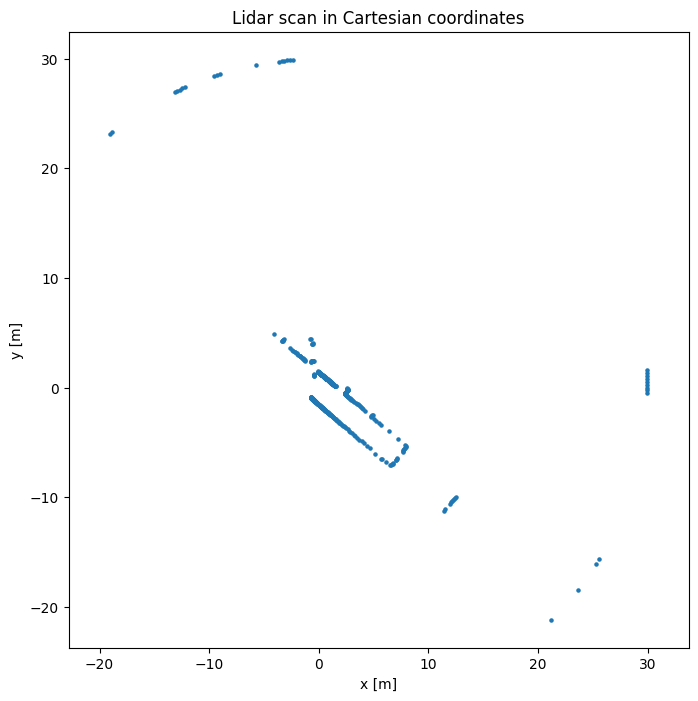

In [3]:
# Why lidar data needs this conversion: a lidar doesn't measure (x, y) positions
# directly. It measures distance ('r', how far away the nearest obstacle is) at
# each of many fixed angular steps ('theta') as it sweeps around. To plot these
# readings as points in a normal 2D scatter plot, each (distance, angle) pair
# has to be converted to Cartesian coordinates using basic trigonometry
# (x = r*cos(theta), y = r*sin(theta)).
# How the angle array is built: since the lidar sweeps from +135 to -135 degrees
# in equal steps, np.linspace(135, -135, len(laser)) generates one evenly-spaced
# angle per distance reading in the file, matching each row of 'laser' to the
# angle it was measured at; np.deg2rad() then converts these to radians, since
# numpy's functions expect radians rather than degrees.
# Why filter out invalid readings first: a lidar reports 0 or infinity for a
# beam that got no valid return. Including these as if they were real distance
# measurements would place spurious points at the origin or at infinity,
# corrupting the scan. np.isfinite(laser) & (laser > 0) keeps only valid,
# positive, finite readings (and their corresponding angles) before converting
# to x/y.
# Why plt.axis('equal'): this forces the x and y axes to use the same physical
# scale.
# Convert to x and y coordinates. The lidar sweeps from +135 deg to -135 deg in
# equal steps, one measurement sper row of `laser`.
angles_deg = np.linspace(135, -135, len(laser))
angles_rad = np.deg2rad(angles_deg)

# A reading of 0 (or inf) usually means "no return" for that beam. Drop those
# before using the data.
valid = np.isfinite(laser) & (laser > 0)
r = laser[valid]
theta = angles_rad[valid]

x = r * np.cos(theta)
y = r * np.sin(theta)

plt.figure(figsize=(8, 8))
plt.scatter(x, y, s=5)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Lidar scan in Cartesian coordinates")
plt.axis("equal")
plt.show()

## Exercise 3.2

We would like to locate one of the walls in the dataset. To do so we will use [Ransac](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RANSACRegressor.html) to fine the best line fit in the noisy data. A Ransac regressor is initialized the following way using sklearn:

In [4]:
# Why RANSAC instead of OLS: a lidar scan of a hallway typically contains points
# from multiple different walls at once (plus some scattered noise). A hallway
# isn't one single line, so fitting an ordinary regression line to all the points
# at once would produce a meaningless average that doesn't track any real wall.
# RANSAC instead searches for a line that a large subset of the points agree
# with, essentially treating every point that doesn't belong to that one wall
# as an "outlier" to be ignored, rather than letting it pull the fit off course
# as OLS would. sklearn.linear_model.RANSACRegressor() is created here with its
# default settings (an internal linear regressor as the base estimator, and default
# inlier-distance/iteration parameters).
ransac = linear_model.RANSACRegressor()

Now that we have our Ransac regressor we can fit it to a dataset (x,y):

In [5]:
# Why reshape x first: sklearn estimators expect their input features as a 2D
# array of shape (n_samples, n_features). x.reshape(-1, 1) turns the flat 1D
# x array into the required (N, 1) column shape.
# Why treat x as input and y as output: this works well as long as the wall
# being fit isn't oriented close to vertical in this coordinate frame (a
# perfectly vertical wall would have many different y values for virtually the
# same x, which a "y as a function of x" model can't represent well).
# RANSACRegressor expects a 2D array of features.
X = x.reshape(-1, 1)
ransac.fit(X, y)

,estimator,None
,min_samples,None
,residual_threshold,None
,is_data_valid,None
,is_model_valid,None
,max_trials,100
,max_skips,inf
,stop_n_inliers,inf
,stop_score,inf
,stop_probability,0.99
,loss,'absolute_error'


Finally, to get the fitted line we can use the predict function. As an argument this takes the x values in which the line will be predicted:

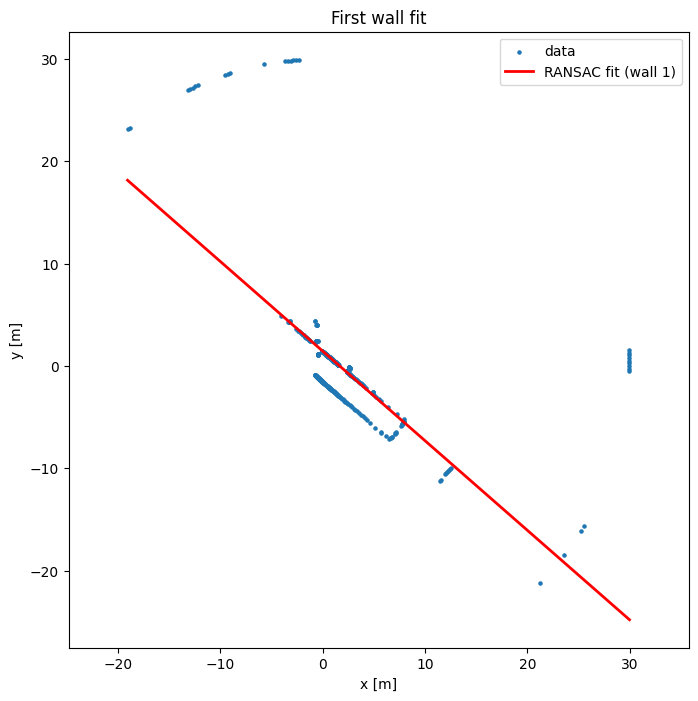

In [6]:
# Why only 2 points (line_x = linspace(..., 2)): a straight line is determined
# by just two points. Generating predictions at the minimum and maximum x values
# is enough to draw a straight line across the full width of the data with
# plt.plot(), since matplotlib just connects the given points with a straight
# segment. The resulting plot overlays this fitted red line on top of the raw
# scatter points.
# Predict line.
line_x = np.linspace(x.min(), x.max(), 2).reshape(-1, 1)
line_y = ransac.predict(line_x)

plt.figure(figsize=(8, 8))
plt.scatter(x, y, s=5, label="data")
plt.plot(line_x, line_y, color="red", linewidth=2, label="RANSAC fit (wall 1)")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("First wall fit")
plt.axis("equal")
plt.legend()
plt.show()

Plot the line on top of the scatterplot from before to see the fit.

## Exercise 3.3

To see which data points were used to make the line fit and which were deemed outliers, we can use the function ransac.inlier_mask_

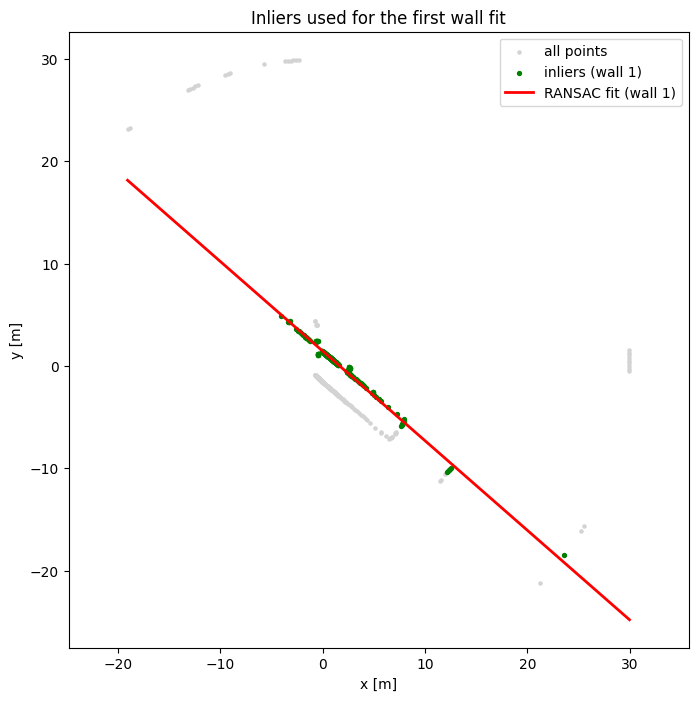

In [7]:
# Why ransac.inlier_mask_: after fitting, RANSAC internally keeps a boolean
# array marking which input points were considered consistent with (i.e. close
# enough to) the final chosen line. This lets us directly inspect and visualize
# RANSAC's own judgment of "which points belong to this wall", rather than just
# seeing the fitted line itself without knowing which points supported it.
# How the plot highlights this: all points are first plotted in light gray as
# background context, then just the inlier points
# (x[ransac.inlier_mask_], y[ransac.inlier_mask_]) are plotted again on
# top in green.
plt.figure(figsize=(8, 8))
plt.scatter(x, y, s=5, color="lightgray", label="all points")
plt.scatter(
    x[ransac.inlier_mask_],
    y[ransac.inlier_mask_],
    color="green",
    s=8,
    label="inliers (wall 1)",
)
plt.plot(line_x, line_y, color="red", linewidth=2, label="RANSAC fit (wall 1)")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Inliers used for the first wall fit")
plt.axis("equal")
plt.legend()
plt.show()


Find the second hallway wall using another Ransac fit and plot it together with the data points and the first ransac fit.

Hint: Use the outliers from the first Ransac.

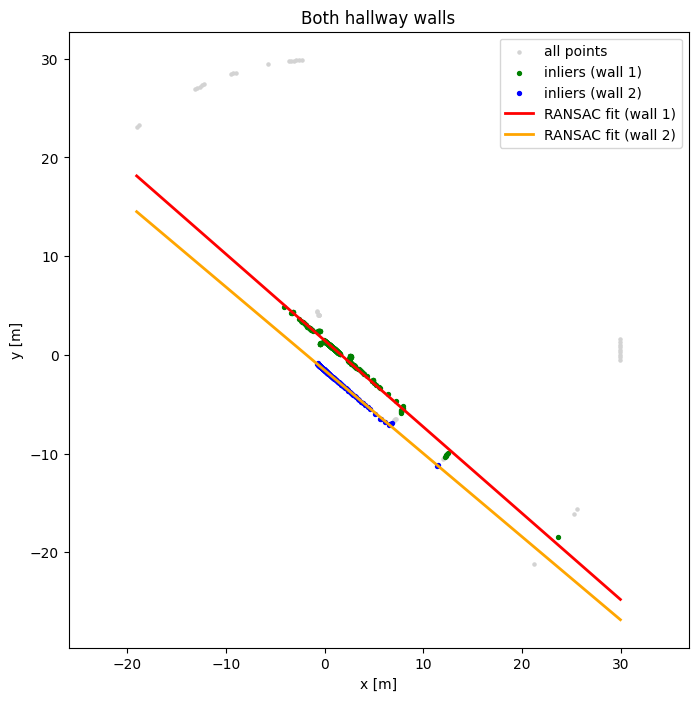

In [8]:
# Why exclude the first wall's inliers before fitting again: if we ran a
# second RANSAC fit on the full original dataset, it would most likely just
# re-discover the same first wall again (since that's still the largest line in
# the data). By first removing the points already claimed by wall 1 (via
# np.logical_not(ransac.inlier_mask_) to get everything that isn't an inlier of
# the first fit, the second RANSAC call is forced to search among only the
# remaining points, which lets the second-most-prominent wall now become the
# strongest line for it to discover. The rest of the cell repeats the same
# pattern used for the first wall, then combines everything into one final plot:
# all points in light gray, each wall's own inliers highlighted in a different
# color (green for wall 1, blue for wall 2), and both fitted lines drawn
# together (red and orange).
ransac2 = linear_model.RANSACRegressor()

# Find the second hallway wall. Use the outliers from the first RANSAC fit as
# input. The first wall's inliers are excluded so the second fit isn't biased
# towards points that already belong to wall 1.
outlier_mask = np.logical_not(ransac.inlier_mask_)
x2 = x[outlier_mask]
y2 = y[outlier_mask]

ransac2.fit(x2.reshape(-1, 1), y2)

line_x2 = np.linspace(x2.min(), x2.max(), 2).reshape(-1, 1)
line_y2 = ransac2.predict(line_x2)

plt.figure(figsize=(8, 8))
plt.scatter(x, y, s=5, color="lightgray", label="all points")
plt.scatter(
    x[ransac.inlier_mask_],
    y[ransac.inlier_mask_],
    color="green",
    s=8,
    label="inliers (wall 1)",
)
plt.scatter(
    x2[ransac2.inlier_mask_],
    y2[ransac2.inlier_mask_],
    color="blue",
    s=8,
    label="inliers (wall 2)",
)
plt.plot(line_x, line_y, color="red", linewidth=2, label="RANSAC fit (wall 1)")
plt.plot(
    line_x2, line_y2, color="orange", linewidth=2, label="RANSAC fit (wall 2)"
)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Both hallway walls")
plt.axis("equal")
plt.legend()
plt.show()
